# Практическая работа 6.2. Обучение модели PyTorch

В notebook используется заранее подготовленный датасет мебели `train / validation / test`. Обучаются две модели: без аугментации и с `TrivialAugmentWide`.


## Импорты


In [1]:
from __future__ import annotations

import os
from pathlib import Path

PRACTICE_DIR = Path.cwd()
CACHE_DIR = PRACTICE_DIR / ".cache"
DATA_DIR = PRACTICE_DIR / ".data"
MPL_CACHE_DIR = CACHE_DIR / "matplotlib"

for directory in (CACHE_DIR, DATA_DIR, MPL_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

os.environ["MPLCONFIGDIR"] = str(MPL_CACHE_DIR)


In [2]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader
from torchinfo import summary
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 64
EPOCHS = 5
IMAGE_SIZE = (128, 128)
NUM_WORKERS = 0

PREPARED_DATASET_DIR = DATA_DIR / "furniture-image-dataset-prepared"
TRAIN_DIR = PREPARED_DATASET_DIR / "train"
VALIDATION_DIR = PREPARED_DATASET_DIR / "validation"
TEST_DIR = PREPARED_DATASET_DIR / "test"

if not TRAIN_DIR.exists():
    raise FileNotFoundError(
        "Не найден подготовленный датасет. Сначала выполните notebook 6.1."
    )

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"PyTorch: {torch.__version__}")
print(f"Устройство: {device}")


PyTorch: 2.11.0
Устройство: mps


## Подготовленный датасет

Во второй части используется уже готовая структура папок `train / validation / test`, поэтому данные читаются через `torchvision.datasets.ImageFolder`.


In [3]:
def count_images_by_class(split_dir: Path) -> dict[str, int]:
    """
    Считает количество изображений в каждом классе выбранного split.

    Parameters
    ----------
    split_dir : Path
        Каталог split `train`, `validation` или `test`.

    Returns
    -------
    dict[str, int]
        Количество изображений по классам.
    """
    return {
        class_dir.name: len(list(class_dir.glob("*.jpeg")))
        for class_dir in sorted(split_dir.iterdir())
        if class_dir.is_dir()
    }


In [4]:
train_class_counts = count_images_by_class(TRAIN_DIR)
validation_class_counts = count_images_by_class(VALIDATION_DIR)
test_class_counts = count_images_by_class(TEST_DIR)
class_names = list(train_class_counts.keys())

print(f"Train: {sum(train_class_counts.values())}")
print(f"Validation: {sum(validation_class_counts.values())}")
print(f"Test: {sum(test_class_counts.values())}")
print("Классы:", class_names)


Train: 10500
Validation: 2250
Test: 2250
Классы: ['almirah', 'chair', 'fridge', 'table', 'television']


## Превью изображений


Random image path: /Users/mikhail/Developer/SUSU.PE/СП-М-О-КЗ-2025/Практика/Практика 6 - Классификация изображений с использованием PyTorch/.data/furniture-image-dataset-prepared/train/almirah/image_2661.jpeg
Image class: almirah
Image height: 191
Image width: 232


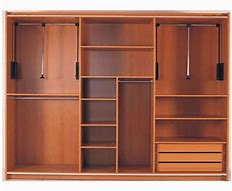

In [5]:
image_path_list = list(PREPARED_DATASET_DIR.glob("*/*/*.jpeg"))
random_image_path = random.choice(image_path_list)
image_class = random_image_path.parent.stem
img = Image.open(random_image_path)

print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img


Отобразить изображение можно с помощью `matplotlib.pyplot.imshow()`, за исключением того, что сначала нам нужно преобразовать изображение в массив `NumPy`.


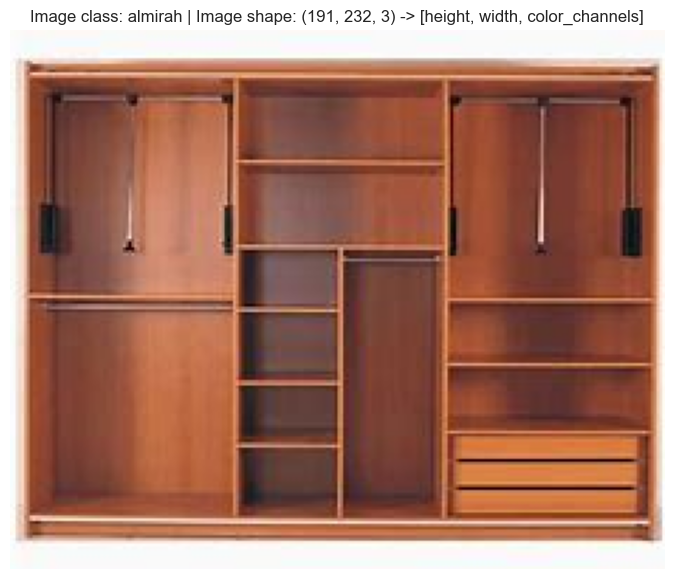

In [6]:
img_as_array = np.asarray(img)

plt.figure(figsize=(10, 7))
plt.imshow(img_as_array)
plt.title(f"Image class: {image_class} | Image shape: {img_as_array.shape} -> [height, width, color_channels]")
plt.axis(False);


<p>Преобразование данных
Прежде чем использовать изображения в PyTorch, необходимо:
- перевести изображение в тензоры;
- записать набор данных в `Dataset`, а затем в `DataLoader`.


<p>Преобразование данных с помощью torchvision.transforms


In [7]:
data_transform = transforms.Compose([
    transforms.Resize(size=IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])


In [8]:
def plot_transformed_images(image_paths, transform, n=3, seed=None):
    """Показывает несколько изображений до и после преобразования."""
    random.seed(seed)
    random_image_paths = random.sample(image_paths, k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(1, 2)
            ax[0].imshow(f)
            ax[0].set_title(f"Original \nSize: {f.size}")
            ax[0].axis("off")

            transformed_image = transform(f).permute(1, 2, 0)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)


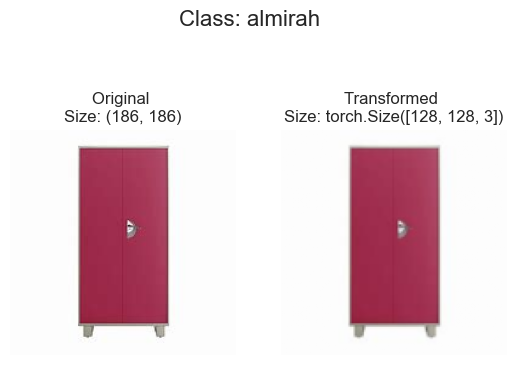

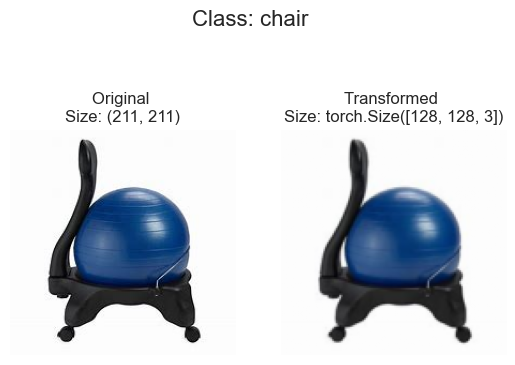

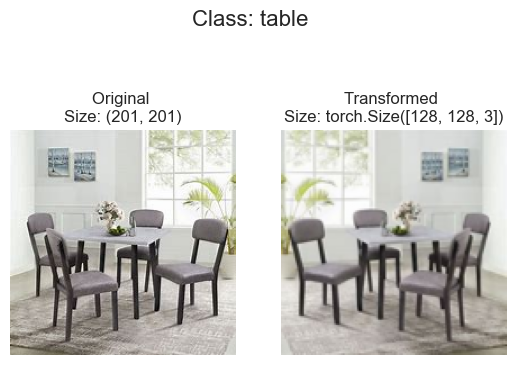

In [9]:
plot_transformed_images(
    image_path_list,
    transform=data_transform,
    n=3,
    seed=None
)


## DataLoader

Для обучения и оценки используются три `ImageFolder`: для `train`, `validation` и `test`. Преобразования изображений будут задаваться отдельно для каждого эксперимента.


In [10]:
preview_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=data_transform)
class_names = preview_dataset.classes
class_dict = preview_dataset.class_to_idx

print(f"Preview dataset: {preview_dataset}")
print(class_dict)


Preview dataset: Dataset ImageFolder
    Number of datapoints: 10500
    Root location: /Users/mikhail/Developer/SUSU.PE/СП-М-О-КЗ-2025/Практика/Практика 6 - Классификация изображений с использованием PyTorch/.data/furniture-image-dataset-prepared/train
    StandardTransform
Transform: Compose(
               Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )
{'almirah': 0, 'chair': 1, 'fridge': 2, 'table': 3, 'television': 4}


In [11]:
img, label = preview_dataset[0][0], preview_dataset[0][1]
print(f"Image tensor:\n{img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")


Image tensor:
tensor([[[0.2353, 0.2275, 0.2314,  ..., 0.5529, 0.5765, 0.5725],
         [0.3137, 0.2471, 0.2196,  ..., 0.6667, 0.6078, 0.5647],
         [0.3020, 0.2431, 0.2667,  ..., 0.5686, 0.5608, 0.5569],
         ...,
         [0.5922, 0.5922, 0.5922,  ..., 0.6863, 0.6824, 0.6824],
         [0.5804, 0.5843, 0.5843,  ..., 0.6941, 0.6941, 0.6941],
         [0.5725, 0.5765, 0.5765,  ..., 0.6941, 0.6863, 0.6863]],

        [[0.1608, 0.1451, 0.1451,  ..., 0.6275, 0.6510, 0.6392],
         [0.2235, 0.1529, 0.1294,  ..., 0.7412, 0.6824, 0.6314],
         [0.1843, 0.1333, 0.1686,  ..., 0.6392, 0.6314, 0.6275],
         ...,
         [0.5725, 0.5725, 0.5725,  ..., 0.6667, 0.6627, 0.6627],
         [0.5608, 0.5647, 0.5647,  ..., 0.6745, 0.6745, 0.6745],
         [0.5529, 0.5569, 0.5569,  ..., 0.6745, 0.6667, 0.6667]],

        [[0.4667, 0.4196, 0.3765,  ..., 0.6941, 0.7176, 0.7020],
         [0.5333, 0.4353, 0.3647,  ..., 0.8000, 0.7412, 0.6941],
         [0.5020, 0.4196, 0.4078,  ..., 0.70

Сейчас изображения представлены в виде тензора, а метки представлены в виде целых чисел, относящихся к определенному классу.


Построим тензор с помощью `matplotlib`. Сначала изменяем порядок представления, чтобы была совместимость.


Original shape: torch.Size([3, 128, 128]) -> [color_channels, height, width]
Image permute shape: torch.Size([128, 128, 3]) -> [height, width, color_channels]


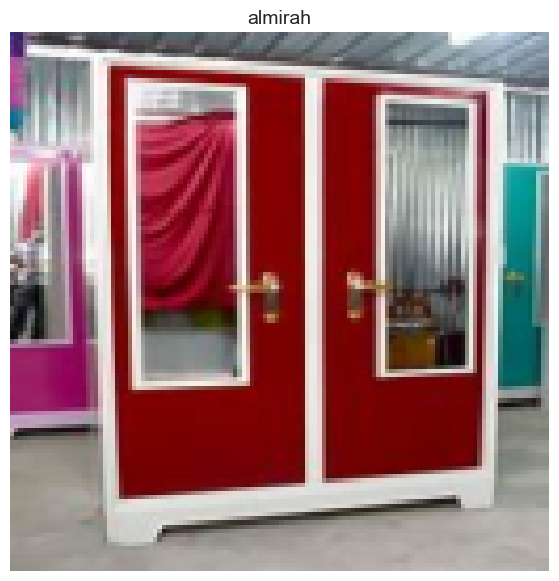

In [12]:
img_permute = img.permute(1, 2, 0)

print(f"Original shape: {img.shape} -> [color_channels, height, width]")
print(f"Image permute shape: {img_permute.shape} -> [height, width, color_channels]")

plt.figure(figsize=(10, 7))
plt.imshow(img.permute(1, 2, 0))
plt.axis("off")
plt.title(class_names[label], fontsize=14);


In [13]:
def display_random_images(dataset, classes=None, n=10, display_shape=True, seed=None):
    """Отображает несколько случайных изображений из Dataset."""
    if n > 10:
        n = 10
        display_shape = False
        print("For display purposes, n shouldn't be larger than 10, setting to 10 and removing shape display.")

    if seed:
        random.seed(seed)

    random_samples_idx = random.sample(range(len(dataset)), k=n)
    plt.figure(figsize=(16, 8))

    for i, targ_sample in enumerate(random_samples_idx):
        targ_image, targ_label = dataset[targ_sample][0], dataset[targ_sample][1]
        targ_image_adjust = targ_image.permute(1, 2, 0)

        plt.subplot(1, n, i + 1)
        plt.imshow(targ_image_adjust)
        plt.axis("off")

        if classes:
            title = f"class: {classes[targ_label]}"
            if display_shape:
                title = title + f"\nshape: {targ_image_adjust.shape}"
            plt.title(title)


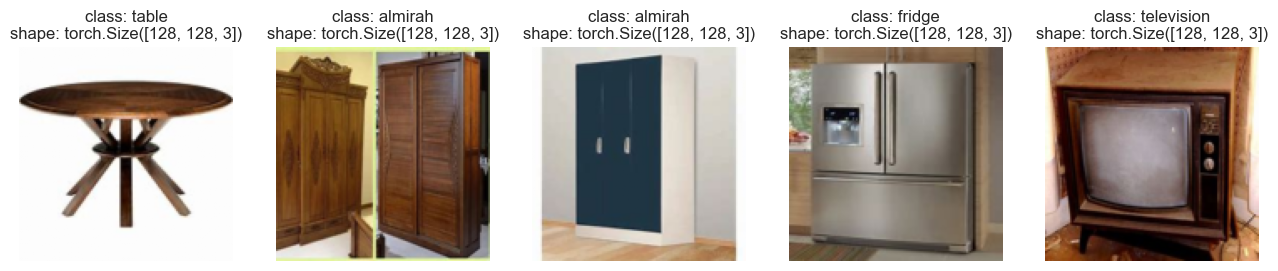

In [14]:
display_random_images(
    preview_dataset,
    n=5,
    classes=class_names,
    seed=None
)


In [15]:
def make_dataloaders(
    train_transform: transforms.Compose,
    eval_transform: transforms.Compose,
) -> tuple[DataLoader, DataLoader, DataLoader, list[str]]:
    """
    Создает DataLoader для train, validation и test выборок.

    Parameters
    ----------
    train_transform : transforms.Compose
        Преобразования для обучающих изображений.
    eval_transform : transforms.Compose
        Преобразования для validation и test изображений.

    Returns
    -------
    tuple[DataLoader, DataLoader, DataLoader, list[str]]
        DataLoader для train, validation, test и список классов.
    """
    train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
    validation_dataset = datasets.ImageFolder(VALIDATION_DIR, transform=eval_transform)
    test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )

    return train_loader, validation_loader, test_loader, train_dataset.classes


## Модель

Модель построена по схеме из методического примера. Она состоит из двух сверточных блоков `Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d` и простого классификатора `Flatten -> Linear`.


In [16]:
class FurnitureCNN(nn.Module):
    """
    Сверточная нейронная сеть для классификации пяти видов мебели.
    """

    def __init__(
        self,
        input_shape: int,
        hidden_units: int,
        output_shape: int,
    ) -> None:
        """
        Создает сверточные блоки и классификатор.

        Parameters
        ----------
        input_shape : int
            Количество входных каналов изображения.
        hidden_units : int
            Количество каналов в сверточных слоях.
        output_shape : int
            Количество классов в задаче.
        """
        super().__init__()

        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(
                in_channels=input_shape,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1,
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1,
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                hidden_units * (IMAGE_SIZE[0] // 4) * (IMAGE_SIZE[1] // 4),
                output_shape,
            ),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Выполняет прямой проход изображения через модель.

        Parameters
        ----------
        x : torch.Tensor
            Batch изображений формы (N, 3, H, W).

        Returns
        -------
        torch.Tensor
            Logits для каждого класса.
        """
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        return self.classifier(x)


In [17]:
model_for_summary = FurnitureCNN(
    input_shape=3,
    hidden_units=10,
    output_shape=len(class_names),
).to(device)
loss_fn = nn.CrossEntropyLoss()

model_for_summary


FurnitureCNN(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=10240, out_features=5, bias=True)
  )
)

## Проверка структуры модели


In [18]:
summary(model_for_summary, input_size=(1, 3, IMAGE_SIZE[0], IMAGE_SIZE[1]), device=device)


Layer (type:depth-idx)                   Output Shape              Param #
FurnitureCNN                             [1, 5]                    --
├─Sequential: 1-1                        [1, 10, 64, 64]           --
│    └─Conv2d: 2-1                       [1, 10, 128, 128]         280
│    └─ReLU: 2-2                         [1, 10, 128, 128]         --
│    └─Conv2d: 2-3                       [1, 10, 128, 128]         910
│    └─ReLU: 2-4                         [1, 10, 128, 128]         --
│    └─MaxPool2d: 2-5                    [1, 10, 64, 64]           --
├─Sequential: 1-2                        [1, 10, 32, 32]           --
│    └─Conv2d: 2-6                       [1, 10, 64, 64]           910
│    └─ReLU: 2-7                         [1, 10, 64, 64]           --
│    └─Conv2d: 2-8                       [1, 10, 64, 64]           910
│    └─ReLU: 2-9                         [1, 10, 64, 64]           --
│    └─MaxPool2d: 2-10                   [1, 10, 32, 32]           --
├─Sequentia

## Обучение модели


In [19]:
def train_step(
    model: nn.Module,
    dataloader: DataLoader,
    loss_fn: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device,
) -> tuple[float, float]:
    """
    Выполняет одну эпоху обучения модели.

    Parameters
    ----------
    model : nn.Module
        Обучаемая модель.
    dataloader : DataLoader
        DataLoader обучающей выборки.
    loss_fn : nn.Module
        Функция потерь.
    optimizer : torch.optim.Optimizer
        Оптимизатор модели.
    device : torch.device
        Устройство, на котором выполняются вычисления.

    Returns
    -------
    tuple[float, float]
        Средние значения loss и accuracy на обучающей выборке.
    """
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (logits.argmax(dim=1) == labels).sum().item()
        train_count += batch_size

    train_loss = train_loss_sum / train_count
    train_accuracy = train_correct / train_count

    return train_loss, train_accuracy


In [20]:
def test_step(
    model: nn.Module,
    dataloader: DataLoader,
    loss_fn: nn.Module,
    device: torch.device,
) -> tuple[float, float]:
    """
    Оценивает модель на validation или test выборке.

    Parameters
    ----------
    model : nn.Module
        Оцениваемая модель.
    dataloader : DataLoader
        DataLoader validation или test выборки.
    loss_fn : nn.Module
        Функция потерь.
    device : torch.device
        Устройство, на котором выполняются вычисления.

    Returns
    -------
    tuple[float, float]
        Средние значения loss и accuracy на выбранной выборке.
    """
    model.eval()
    test_loss_sum = 0.0
    test_correct = 0
    test_count = 0

    with torch.inference_mode():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = loss_fn(logits, labels)

            batch_size = labels.size(0)
            test_loss_sum += loss.item() * batch_size
            test_correct += (logits.argmax(dim=1) == labels).sum().item()
            test_count += batch_size

    test_loss = test_loss_sum / test_count
    test_accuracy = test_correct / test_count

    return test_loss, test_accuracy


In [21]:
def train(
    model: nn.Module,
    train_dataloader: DataLoader,
    validation_dataloader: DataLoader,
    optimizer: torch.optim.Optimizer,
    loss_fn: nn.Module,
    epochs: int,
    device: torch.device,
) -> dict[str, list[float]]:
    """
    Обучает модель и сохраняет историю изменения метрик.

    Parameters
    ----------
    model : nn.Module
        Обучаемая модель.
    train_dataloader : DataLoader
        DataLoader обучающей выборки.
    validation_dataloader : DataLoader
        DataLoader валидационной выборки.
    optimizer : torch.optim.Optimizer
        Оптимизатор модели.
    loss_fn : nn.Module
        Функция потерь.
    epochs : int
        Количество эпох обучения.
    device : torch.device
        Устройство, на котором выполняются вычисления.

    Returns
    -------
    dict[str, list[float]]
        История изменения loss и accuracy на train и validation.
    """
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": [],
    }

    for epoch in range(1, epochs + 1):
        train_loss, train_accuracy = train_step(
            model=model,
            dataloader=train_dataloader,
            loss_fn=loss_fn,
            optimizer=optimizer,
            device=device,
        )
        validation_loss, validation_accuracy = test_step(
            model=model,
            dataloader=validation_dataloader,
            loss_fn=loss_fn,
            device=device,
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train_loss={train_loss:.4f} | "
            f"train_accuracy={train_accuracy:.4f} | "
            f"validation_loss={validation_loss:.4f} | "
            f"validation_accuracy={validation_accuracy:.4f}"
        )

    return history


## Эксперимент 1: Данные без аугментации


### Преобразование


In [22]:
simple_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
])


### Обучение


In [23]:
simple_train_loader, simple_validation_loader, simple_test_loader, class_names = make_dataloaders(
    train_transform=simple_transform,
    eval_transform=simple_transform,
)

torch.manual_seed(SEED)
simple_model = FurnitureCNN(
    input_shape=3,
    hidden_units=10,
    output_shape=len(class_names),
).to(device)
simple_optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-3)

simple_history = train(
    model=simple_model,
    train_dataloader=simple_train_loader,
    validation_dataloader=simple_validation_loader,
    optimizer=simple_optimizer,
    loss_fn=loss_fn,
    epochs=EPOCHS,
    device=device,
)


Epoch 01/5 | train_loss=1.1017 | train_accuracy=0.5638 | validation_loss=0.6456 | validation_accuracy=0.7698
Epoch 02/5 | train_loss=0.3446 | train_accuracy=0.8805 | validation_loss=0.1629 | validation_accuracy=0.9507
Epoch 03/5 | train_loss=0.0382 | train_accuracy=0.9899 | validation_loss=0.0159 | validation_accuracy=0.9938
Epoch 04/5 | train_loss=0.0030 | train_accuracy=0.9996 | validation_loss=0.0010 | validation_accuracy=1.0000
Epoch 05/5 | train_loss=0.0006 | train_accuracy=1.0000 | validation_loss=0.0005 | validation_accuracy=1.0000


### Графики


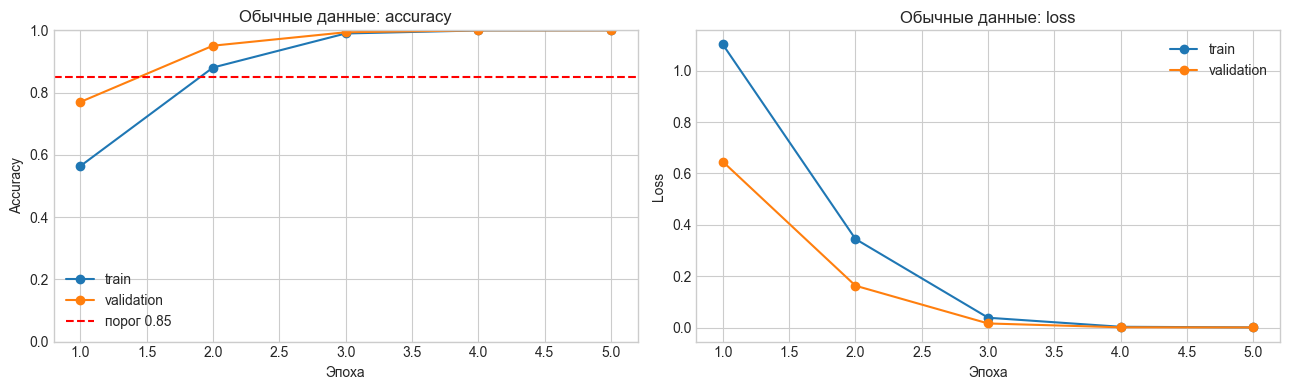

In [24]:
epochs = np.arange(1, len(simple_history["train_accuracy"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, simple_history["train_accuracy"], marker="o", label="train")
axes[0].plot(epochs, simple_history["validation_accuracy"], marker="o", label="validation")
axes[0].axhline(0.85, color="red", linestyle="--", label="порог 0.85")
axes[0].set_title("Обычные данные: accuracy")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].plot(epochs, simple_history["train_loss"], marker="o", label="train")
axes[1].plot(epochs, simple_history["validation_loss"], marker="o", label="validation")
axes[1].set_title("Обычные данные: loss")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


### Оценка качества


In [25]:
simple_model.eval()
simple_test_loss_sum = 0.0
simple_test_correct = 0
simple_test_count = 0
simple_true_labels = []
simple_predicted_labels = []

with torch.inference_mode():
    for images, labels in simple_test_loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = simple_model(images)
        loss = loss_fn(logits, labels)
        predictions = logits.argmax(dim=1).cpu()

        batch_size = labels.size(0)
        simple_test_loss_sum += loss.item() * batch_size
        simple_test_correct += (predictions == labels.cpu()).sum().item()
        simple_test_count += batch_size

        simple_true_labels.append(labels.cpu())
        simple_predicted_labels.append(predictions)

simple_test_loss = simple_test_loss_sum / simple_test_count
simple_test_accuracy = simple_test_correct / simple_test_count
simple_true_labels = torch.cat(simple_true_labels).numpy()
simple_predicted_labels = torch.cat(simple_predicted_labels).numpy()

print(f"Test loss: {simple_test_loss:.4f}")
print(f"Test accuracy: {simple_test_accuracy:.4f}")


Test loss: 0.0004
Test accuracy: 1.0000


### Матрица ошибок


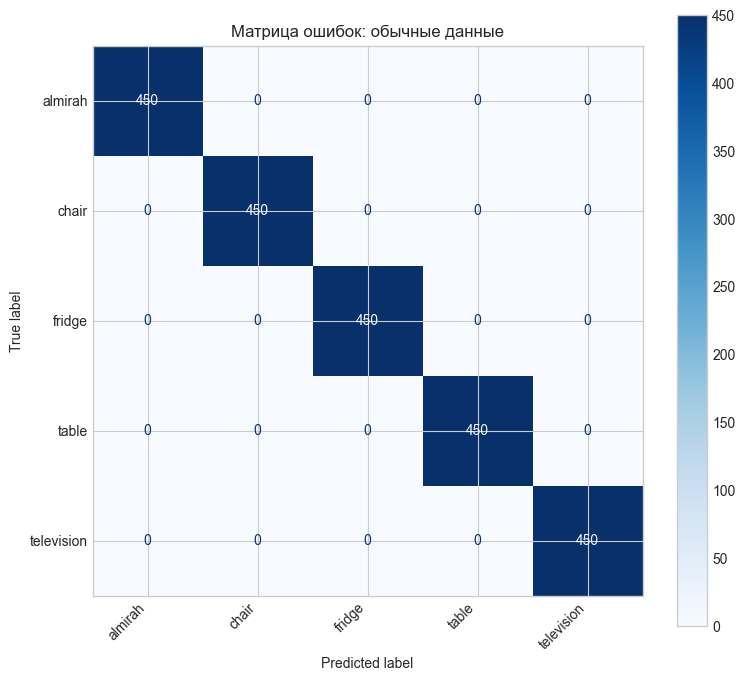

In [26]:
simple_confusion_matrix = confusion_matrix(
    simple_true_labels,
    simple_predicted_labels,
    labels=np.arange(len(class_names)),
)

fig, axis = plt.subplots(figsize=(8, 7))
display = ConfusionMatrixDisplay(
    confusion_matrix=simple_confusion_matrix,
    display_labels=class_names,
)
display.plot(ax=axis, cmap="Blues", values_format="d", colorbar=True)
axis.set_title("Матрица ошибок: обычные данные")
axis.set_xticklabels(class_names, rotation=45, ha="right")

plt.tight_layout()
plt.show()


## Эксперимент 2: Данные с аугментацией


### Преобразование


In [27]:
augmented_train_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor(),
])

augmented_eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
])


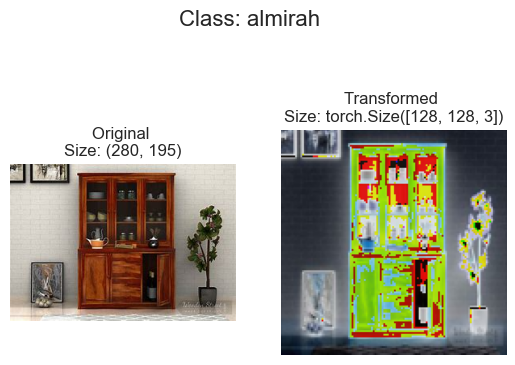

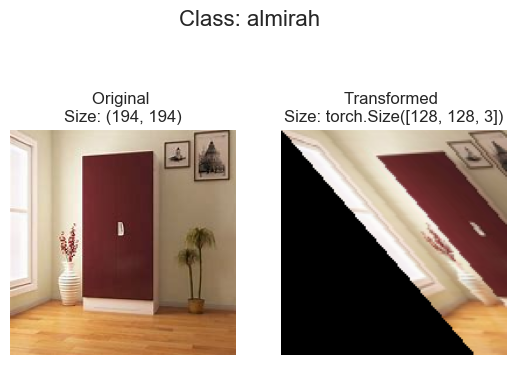

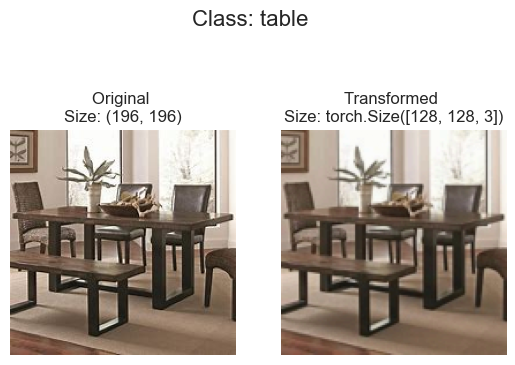

In [28]:
plot_transformed_images(
    image_path_list,
    transform=augmented_train_transform,
    n=3,
    seed=None
)


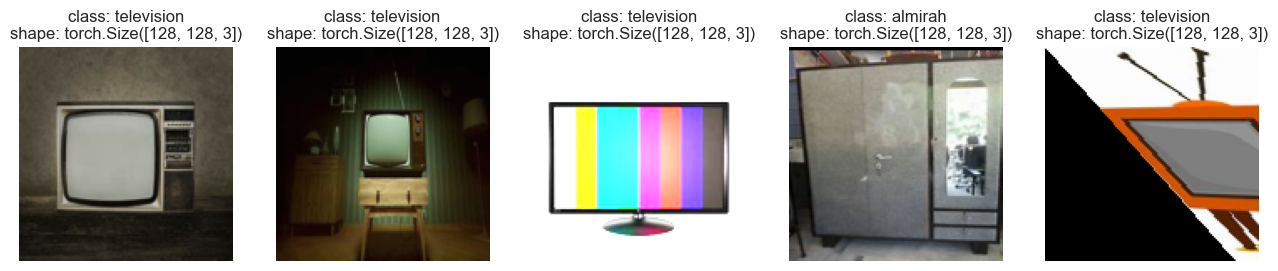

In [29]:
augmented_preview_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=augmented_train_transform,
)

display_random_images(
    augmented_preview_dataset,
    n=5,
    classes=class_names,
    seed=None
)


### Обучение


In [30]:
augmented_train_loader, augmented_validation_loader, augmented_test_loader, class_names = make_dataloaders(
    train_transform=augmented_train_transform,
    eval_transform=augmented_eval_transform,
)

torch.manual_seed(SEED)
augmented_model = FurnitureCNN(
    input_shape=3,
    hidden_units=10,
    output_shape=len(class_names),
).to(device)
augmented_optimizer = torch.optim.Adam(augmented_model.parameters(), lr=1e-3)

augmented_history = train(
    model=augmented_model,
    train_dataloader=augmented_train_loader,
    validation_dataloader=augmented_validation_loader,
    optimizer=augmented_optimizer,
    loss_fn=loss_fn,
    epochs=EPOCHS,
    device=device,
)


Epoch 01/5 | train_loss=1.4373 | train_accuracy=0.3888 | validation_loss=1.0485 | validation_accuracy=0.6453
Epoch 02/5 | train_loss=1.0049 | train_accuracy=0.6304 | validation_loss=0.4457 | validation_accuracy=0.8618
Epoch 03/5 | train_loss=0.7011 | train_accuracy=0.7518 | validation_loss=0.2327 | validation_accuracy=0.9444
Epoch 04/5 | train_loss=0.5987 | train_accuracy=0.7953 | validation_loss=0.1174 | validation_accuracy=0.9800
Epoch 05/5 | train_loss=0.5107 | train_accuracy=0.8263 | validation_loss=0.0860 | validation_accuracy=0.9929


### Графики


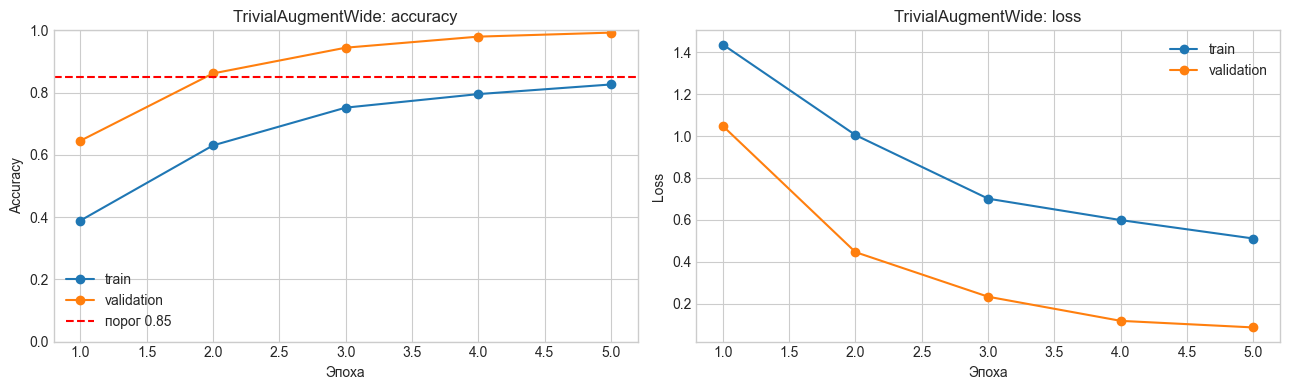

In [31]:
epochs = np.arange(1, len(augmented_history["train_accuracy"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, augmented_history["train_accuracy"], marker="o", label="train")
axes[0].plot(epochs, augmented_history["validation_accuracy"], marker="o", label="validation")
axes[0].axhline(0.85, color="red", linestyle="--", label="порог 0.85")
axes[0].set_title("TrivialAugmentWide: accuracy")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].plot(epochs, augmented_history["train_loss"], marker="o", label="train")
axes[1].plot(epochs, augmented_history["validation_loss"], marker="o", label="validation")
axes[1].set_title("TrivialAugmentWide: loss")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


### Оценка качества


In [32]:
augmented_model.eval()
augmented_test_loss_sum = 0.0
augmented_test_correct = 0
augmented_test_count = 0
augmented_true_labels = []
augmented_predicted_labels = []

with torch.inference_mode():
    for images, labels in augmented_test_loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = augmented_model(images)
        loss = loss_fn(logits, labels)
        predictions = logits.argmax(dim=1).cpu()

        batch_size = labels.size(0)
        augmented_test_loss_sum += loss.item() * batch_size
        augmented_test_correct += (predictions == labels.cpu()).sum().item()
        augmented_test_count += batch_size

        augmented_true_labels.append(labels.cpu())
        augmented_predicted_labels.append(predictions)

augmented_test_loss = augmented_test_loss_sum / augmented_test_count
augmented_test_accuracy = augmented_test_correct / augmented_test_count
augmented_true_labels = torch.cat(augmented_true_labels).numpy()
augmented_predicted_labels = torch.cat(augmented_predicted_labels).numpy()

print(f"Test loss: {augmented_test_loss:.4f}")
print(f"Test accuracy: {augmented_test_accuracy:.4f}")


Test loss: 0.0819
Test accuracy: 0.9960


### Матрица ошибок


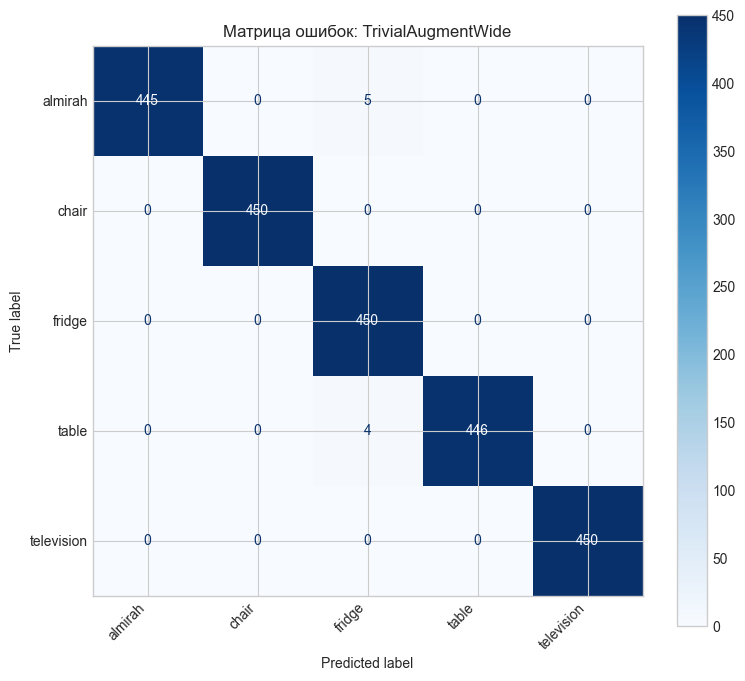

In [33]:
augmented_confusion_matrix = confusion_matrix(
    augmented_true_labels,
    augmented_predicted_labels,
    labels=np.arange(len(class_names)),
)

fig, axis = plt.subplots(figsize=(8, 7))
display = ConfusionMatrixDisplay(
    confusion_matrix=augmented_confusion_matrix,
    display_labels=class_names,
)
display.plot(ax=axis, cmap="Blues", values_format="d", colorbar=True)
axis.set_title("Матрица ошибок: TrivialAugmentWide")
axis.set_xticklabels(class_names, rotation=45, ha="right")

plt.tight_layout()
plt.show()


## Сравнение моделей


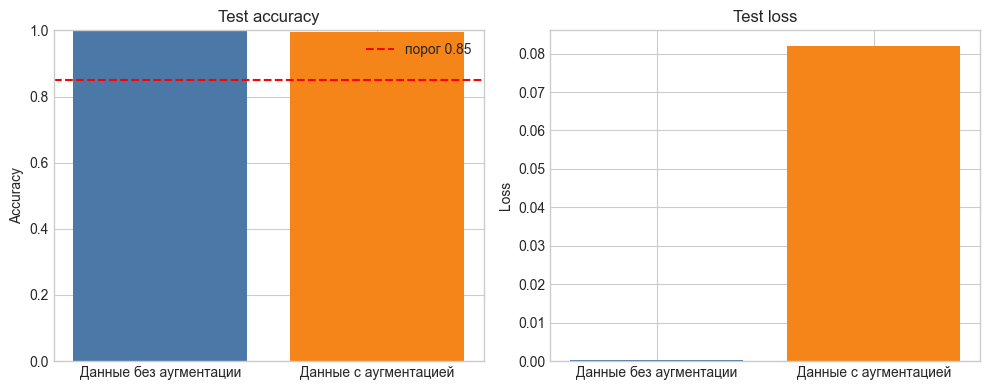

In [34]:
model_names = ["Данные без аугментации", "Данные с аугментацией"]
test_accuracies = [simple_test_accuracy, augmented_test_accuracy]
test_losses = [simple_test_loss, augmented_test_loss]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(model_names, test_accuracies, color=["#4c78a8", "#f58518"])
axes[0].axhline(0.85, color="red", linestyle="--", label="порог 0.85")
axes[0].set_title("Test accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].bar(model_names, test_losses, color=["#4c78a8", "#f58518"])
axes[1].set_title("Test loss")
axes[1].set_ylabel("Loss")

plt.tight_layout()
plt.show()
